In [5]:
#load the two datasets
from pathlib import Path
import pandas as pd

data_dir = Path.cwd() / 'data'
file_path_obama = data_dir / 'Obama_Speeches.csv'
file_path_trump = data_dir / 'Trump_Labeled_Combined_Rev_Speeches_Final_9-24-2024.csv'

full_obama = pd.read_csv(file_path_obama)
full_trump = pd.read_csv(file_path_trump)

#sort original dataset by date

full_trump['date'] = pd.to_datetime(full_trump['date'])
full_trump = (full_trump.sort_values('date').reset_index(drop=True))

obama = pd.concat([full_obama.iloc[:50], full_obama.iloc[-50:]]).reset_index(drop=True)
trump = pd.concat([full_trump.iloc[:50], full_trump.iloc[-50:]]).reset_index(drop=True)

#(sub 1.2 working with data)

In [ ]:
#extract the relevant columns/data and change the order of the columns
trump = trump[['date', 'title','transcript', 'word_count', 'stop_word_count', 'non_stopwords']].copy()
#change order of columns
obama = obama[['date', 'title', 'transcript']]

#(sub 1.3 working with data)

,date,title,transcript,word_count,stop_word_count,non_stopwords
0,2015-07-20,donald-trump-says-i-like-people-who-werent-cap...,excuse me. okay. let’s. you got to let me spea...,1045,514,excuse okay lets got let speak though frank in...
1,2016-04-19,donald-trump-michigan-speech-transcript-asks-b...,thank you very much. thank you. thank you. wha...,4151,2056,thank much thank thank crowd wow look boy crow...
2,2016-09-26,donald-trump-vs-hillary-clinton-1st-presidenti...,thank you. lester. our jobs are fleeing the co...,8438,4499,thank lester jobs fleeing country theyre going...
3,2016-10-09,donald-trump-vs-hillary-clinton-2nd-presidenti...,"well, i actually agree with that. i agree with...",6731,3537,well actually agree agree everything said bega...
4,2016-10-19,donald-trump-vs-hillary-clinton-3rd-presidenti...,"well, first of all, it’s great to be with you ...",6497,3464,well first great thank everybody supreme court...
...,...,...,...,...,...,...
95,2024-09-16,trump-rally-in-las-vegas,"thank you very much, everybody. hello, las veg...",10209,5056,thank much everybody hello las vegas hello las...
96,2024-09-16,donald-trump-takes-questions-from-reporters,get them out. and it’s an honor that you’re. i...,4194,2226,get honor youre youd like take questions excus...
97,2024-09-19,donald-trump-rally-on-9-18-24-in-uniondale,"kamala harris, the radical left democrat polit...",11135,5504,kamala harris radical left democrat politician...
98,2024-09-23,trump-rally-in-north-carolina-2,"oh, what a crowd this is. that’s a big, beauti...",9898,4951,oh crowd thats big beautiful flew said thats l...


## Visualisering

In [7]:
#add 'word_count', 'stop_word_count', 'non_stopwords' to the obama dataset
from gensim.utils import simple_preprocess
from nltk.corpus import stopwords

#tokenize, lowercase, removes punctuation, count the words
obama['word_count'] = [
    len(simple_preprocess(speech, min_len=1, max_len=100))
    for speech in obama['transcript']]

#count the stopwords
stop_words = stopwords.words('english')
obama['stop_word_count'] = [
    len([word for word in simple_preprocess(speech, min_len=1, max_len=100)
         if word in stop_words])
    for speech in obama['transcript']]

#extract non_stopwords
obama['non_stopwords'] = [
    ' '.join([word for word in simple_preprocess(speech)
              if word not in stop_words])
    for speech in obama['transcript']]

print(len(obama))
display(obama.head())

print(len(trump))
display(trump.head())

#(workshop nlp, nlp_canvas.ipynb)

100


,date,title,transcript,word_count,stop_word_count,non_stopwords
0,2009-01-21,President Barack Obama's Inaugural Address,My fellow citizens: I stand here today humbled...,2427,1247,fellow citizens stand today humbled task us gr...
1,2009-01-21,Remarks of the President in Welcoming Senior S...,"Hello, everybody. Please be seated. Still gett...",1546,857,hello everybody please seated still getting us...
2,2009-01-21,Remarks of the President in Welcoming Senior S...,THE PRESIDENT: For the senior staff.\n\n\n\nTH...,34,14,president senior staff president yes number ca...
3,2009-01-23,Remarks by the President Before the Bipartisan...,"Well, it is great to see you. We are here toge...",551,317,well great see together couple weeks first mee...
4,2009-01-24,WEEKLY ADDRESS: President Barack Obama Discuss...,We begin this year and this Administration in ...,819,389,begin year administration midst unprecedented ...


100


,date,title,transcript,word_count,stop_word_count,non_stopwords
0,2015-07-20,donald-trump-says-i-like-people-who-werent-cap...,excuse me. okay. let’s. you got to let me spea...,1045,514,excuse okay lets got let speak though frank in...
1,2016-04-19,donald-trump-michigan-speech-transcript-asks-b...,thank you very much. thank you. thank you. wha...,4151,2056,thank much thank thank crowd wow look boy crow...
2,2016-09-26,donald-trump-vs-hillary-clinton-1st-presidenti...,thank you. lester. our jobs are fleeing the co...,8438,4499,thank lester jobs fleeing country theyre going...
3,2016-10-09,donald-trump-vs-hillary-clinton-2nd-presidenti...,"well, i actually agree with that. i agree with...",6731,3537,well actually agree agree everything said bega...
4,2016-10-19,donald-trump-vs-hillary-clinton-3rd-presidenti...,"well, first of all, it’s great to be with you ...",6497,3464,well first great thank everybody supreme court...


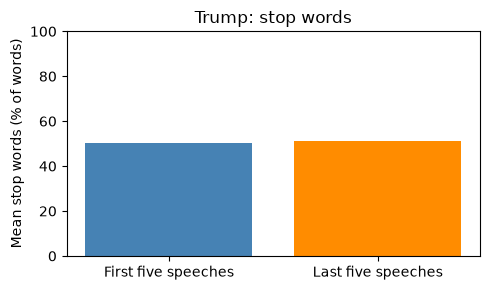

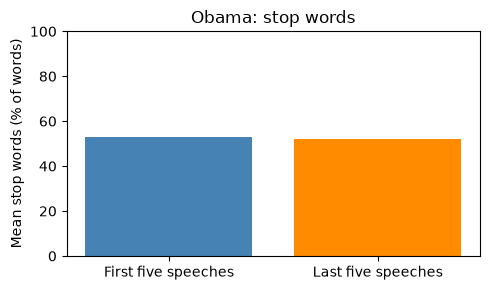

In [9]:
#visualize and compare speeches
import matplotlib.pyplot as plt

#calculate stopwords as a percentage of all words
trump['stop_word_rate'] = (trump['stop_word_count'] / trump['word_count'] * 100)
obama['stop_word_rate'] = (obama['stop_word_count'] / obama['word_count'] * 100)

#trumps first five vs last five speeches
trump_rates = [trump['stop_word_rate'].iloc[:50].mean(),
               trump['stop_word_rate'].iloc[-50:].mean()]

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(['First five speeches', 'Last five speeches'],
       trump_rates,
       color=['steelblue', 'darkorange'])
ax.set_title('Trump: stop words')
ax.set_ylabel('Mean stop words (% of words)')
ax.set_ylim(0,100)
plt.tight_layout()
plt.show()

#obama first five vs last five speeches
obama_rates = [obama['stop_word_rate'].iloc[:50].mean(),
               obama['stop_word_rate'].iloc[-50:].mean()]

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(['First five speeches', 'Last five speeches'],
       obama_rates,
       color=['steelblue', 'darkorange'])
ax.set_title('Obama: stop words')
ax.set_ylabel('Mean stop words (% of words)')
ax.set_ylim(0,100)
plt.tight_layout()
plt.show()

#(sub 1.4 visualisations)

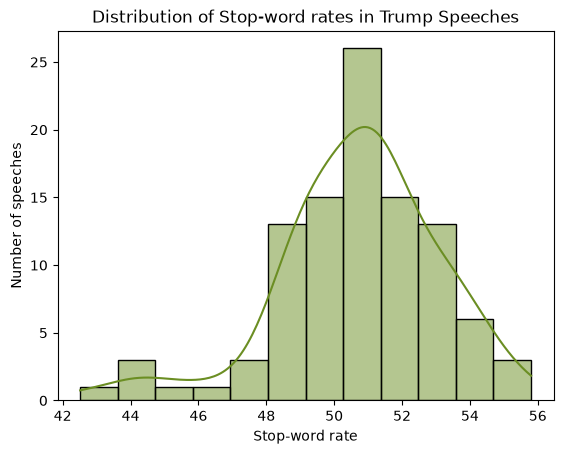

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

stop_word_rate = trump['stop_word_count'] / trump['word_count']

sns.histplot(
    data=trump,
    x='stop_word_rate',
    color = 'olivedrab',
    kde=True
)

plt.xlabel('Stop-word rate')
plt.ylabel('Number of speeches')
plt.title('Distribution of Stop-word rates in Trump Speeches')
plt.show()
